# 00. Sourcing, wrangling, staging

In [1]:
write_data = False

In [4]:
import glob
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

project_dir = Path.cwd()
# https://www.kaggle.com/competitions/m5-forecasting-accuracy/data
data_dir = project_dir / 'Raw Data' # put the CSVs here

In [7]:
# load main datasets
sales = pd.read_csv(data_dir / 'sales_train_validation.csv')
calendar = pd.read_csv(data_dir / 'calendar.csv')
sell_prices = pd.read_csv(data_dir / 'sell_prices.csv')

In [6]:
# convert sales from wide to long format
sales_long = sales.melt(
    id_vars=['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id'],
    var_name='d',
    value_name='units_sold'
)

# add calendar dates and features
sales_long = sales_long.merge(
    calendar[
        ['d', 'date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year',
         'event_name_1', 'event_type_1']
    ],
    on='d',
    how='left',
    validate='many_to_one'
)

sales_long['date'] = pd.to_datetime(sales_long['date'])

# add selling prices
sales_long = sales_long.merge(
    sell_prices[['store_id', 'item_id', 'wm_yr_wk', 'sell_price']],
    on=['store_id', 'item_id', 'wm_yr_wk'],
    how='left',
    validate='many_to_one'
)

sales_long['sell_price'] = sales_long['sell_price'].fillna(0)

KeyboardInterrupt: 

In [4]:
# check whether dates are consecutive
dates = sales_long['date'].drop_duplicates().sort_values()

expected_dates = pd.date_range(
    start=dates.min(),
    end=dates.max(),
    freq='D'
)

missing_dates = expected_dates.difference(dates)

if len(missing_dates) > 0:
    raise ValueError(f'missing dates: {missing_dates.tolist()}')

print('all dates are consecutive')

all dates are consecutive


# Exploratory Data Analysis (EDA)

In [5]:
sales_long.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d,units_sold,date,wm_yr_wk,weekday,wday,month,year,event_name_1,event_type_1,sell_price
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,0.0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,0.0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,0.0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,0.0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,0.0


In [6]:
sales_long.dtypes

id                      object
item_id                 object
dept_id                 object
cat_id                  object
store_id                object
state_id                object
d                       object
units_sold               int64
date            datetime64[ns]
wm_yr_wk                 int64
weekday                 object
wday                     int64
month                    int64
year                     int64
event_name_1            object
event_type_1            object
sell_price             float64
dtype: object

In [7]:
len(sales_long)

58327370

## store_id
All stores seem comparable across all columns, save for max(sell_price) of store_id = WI_2 and WI_3.

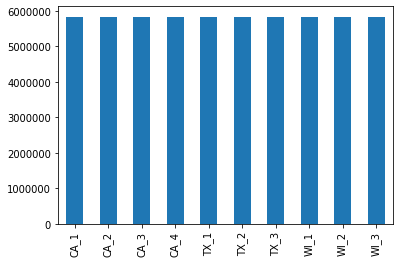

In [8]:
sales_long['store_id'].value_counts().plot(kind='bar')

In [9]:
sales_long.groupby('store_id')[['sell_price']].describe()

sell_price                                                   
              count      mean       std  min   25%   50%   75%     max
store_id                                                              
CA_1      5832737.0  3.556781  3.511821  0.0  1.00  2.87  4.97   30.98
CA_2      5832737.0  3.257548  3.556865  0.0  0.00  2.50  4.88   30.98
CA_3      5832737.0  3.511816  3.500538  0.0  0.98  2.78  4.97   30.98
CA_4      5832737.0  3.460067  3.514982  0.0  0.97  2.77  4.97   30.98
TX_1      5832737.0  3.531633  3.484300  0.0  0.98  2.78  4.97   52.62
TX_2      5832737.0  3.532606  3.469810  0.0  1.00  2.78  4.97   29.97
TX_3      5832737.0  3.496702  3.499848  0.0  0.97  2.74  4.97   30.98
WI_1      5832737.0  3.419145  3.555029  0.0  0.70  2.68  4.97   35.88
WI_2      5832737.0  3.471723  3.549978  0.0  0.97  2.73  4.97   61.46
WI_3      5832737.0  3.547594  3.524324  0.0  0.98  2.84  4.97  107.32

## sell_price
Consider outlier detection/removal/capping for sell_price's at/above 99 percentile.  
It's interesting that FOODS is a distinct group, while HOBBIES has the widest range.  

In [10]:
sales_long.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d,units_sold,date,wm_yr_wk,weekday,wday,month,year,event_name_1,event_type_1,sell_price
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,0.0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,0.0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,0.0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,0.0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,0.0


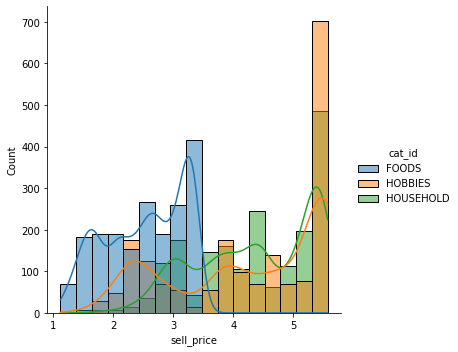

In [11]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning, module='matplotlib')

# plot avgs; raw dataset too large for sns
grp = sales_long.groupby(['d','cat_id'], as_index=False)[['sell_price']].mean()
sns.displot(data=grp, x="sell_price", hue="cat_id", kde=True)

plt.show()

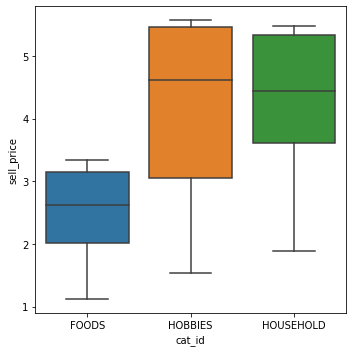

In [12]:
# plot box plots
plt.figure(figsize=(5, 5))
sns.boxplot(data=grp, x='cat_id', y='sell_price')

plt.tight_layout()
plt.show()

90%       7.94
91%       7.98
92%       8.48
93%       8.97
94%       9.50
95%       9.97
96%      10.98
97%      11.97
98%      12.97
99%      15.92
100%    107.32
Name: sell_price, dtype: float64


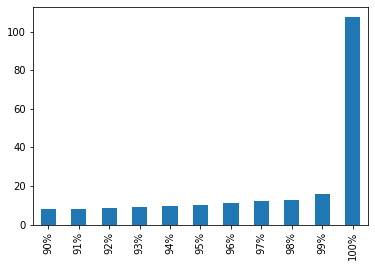

In [13]:
# view the percentiles of sell_price

df = sales_long['sell_price'].describe(percentiles = np.arange(0,1.01,0.01))
df2 = df.loc['90%':'100%']
print(df2)
df2.plot(kind='bar')

## date

In [14]:
d1 = sales_long['date'].min()
d2 = sales_long['date'].max()

print(d1.date(), d2.date())
print(f"~{np.round((d2-d1).days/365)} years")

2011-01-29 2016-04-24
~5.0 years


## event_type_1 and event_name_1
Overall, the least number of units are sold on national holidays.    
We see that Labor Day sells the most, units while Christmas sells the least.

In [15]:
sales_long['event_type_1'].value_counts()

Religious    1585480
National     1554990
Cultural     1067150
Sporting      487840
Name: event_type_1, dtype: int64

In [16]:
sales_long['event_name_1'].value_counts()

SuperBowl              182940
PresidentsDay          182940
LentStart              182940
LentWeek2              182940
StPatricksDay          182940
Purim End              182940
ValentinesDay          182940
Thanksgiving           152450
Halloween              152450
EidAlAdha              152450
VeteransDay            152450
NewYear                152450
Christmas              152450
Chanukah End           152450
LaborDay               152450
OrthodoxChristmas      152450
MartinLutherKingDay    152450
ColumbusDay            152450
IndependenceDay        152450
Eid al-Fitr            152450
Ramadan starts         152450
NBAFinalsEnd           152450
NBAFinalsStart         152450
MemorialDay            152450
Mother's day           152450
Pesach End             152450
Easter                 152450
Father's day           121960
Cinco De Mayo          121960
OrthodoxEaster         121960
Name: event_name_1, dtype: int64

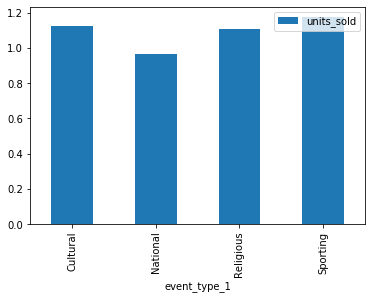

In [17]:
sales_long.groupby('event_type_1')[['units_sold']].mean().plot(kind='bar')

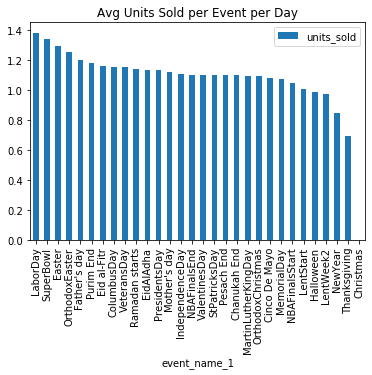

In [18]:
(
    sales_long
    .groupby('event_name_1')[['units_sold']]
    .mean()
    .sort_values('units_sold', ascending = False)
    .plot(kind='bar', title = 'Avg Units Sold per Event per Day')
)

In [19]:
sales_long[sales_long['event_name_1']=='Christmas'][['units_sold']].sum()

units_sold    78
dtype: int64

In [24]:
print(np.min(sorted(sales_long['date'].unique())))
print(np.max(sorted(sales_long['date'].unique())))

2011-01-29T00:00:00.000000000
2016-04-24T00:00:00.000000000


# Write data for downstream modeling
~15 min

In [28]:
import datetime as dt
dt.datetime.now()

datetime.datetime(2026, 10, 24, 13, 6, 20, 20639)

In [29]:
if write_data:    
    # for ML models, don't aggregate on date
    print('rows:', len(sales_long))
    print('memory in GB:', round(
        sales_long.memory_usage(deep=True).sum() / 1024**3, 2
    ))

    # for ML models, keep data on item-store-date level
    sales_long.to_csv(data_dir / 'sales_long.csv', index=False)
else:
    print('write_data == FALSE')

rows: 58327370
memory in GB: 36.65


In [ ]:
dt.datetime.now()

In [30]:
if write_data:
    # for time series, aggregate on date
    sales_long_agg = sales_long.groupby('date', as_index = False)[['units_sold']].sum()

    print('rows:', len(sales_long_agg))
    print('memory in GB:', round(
        sales_long_agg.memory_usage(deep=True).sum() / 1024**3, 2
    ))

    sales_long_agg.to_csv(data_dir / 'sales_long_agg.csv', index=False)
else:
    print('write_data == FALSE')

rows: 1913
memory in GB: 0.0


In [31]:
dt.datetime.now()

datetime.datetime(2026, 10, 24, 13, 21, 17, 83096)